# Where should Bengaluru build its next park? — site selection

The parks notebook asked *"did past parks cool their surroundings?"* This notebook asks the forward-looking question:
**where would a new park cool the most, for the most people?**

**Method**
1. **City-wide model** — sample ~4,000 pixels across Bengaluru (Jan–Apr, recent years) and estimate how much cooler a place is per unit of greenness (NDVI), controlling for built-up area and elevation.
2. **Calibrate** — check the model against the parks you actually measured (`all_parks_comparison.csv` from the parks notebook).
3. **Find candidate land** — open patches ≥ 5 ha (grass / scrub / bare land, low built-up, low NDVI), excluding water, existing parks, airports, military land, campuses and similar (OpenStreetMap).
4. **Score each candidate** — expected cooling if it became a park × residents within 500 m, plus how hot and how un-green the neighbourhood is now.
5. **Outputs** — ranked table, maps, charts and a before/after "what if" for the top site, saved to `data/site_selection/` and `figures/`.

Results are **associations, not guarantees**: real cooling depends on design (tree canopy cools far more than lawn or paving), and LST is surface, not air, temperature. Land availability (ownership, zoning) must be checked on the ground.

## 0. Install & connect

In [3]:
!pip install -q earthengine-api geemap osmnx scikit-learn statsmodels

In [4]:
import ee

PROJECT_ID = 'deft-return-507617-v4'

try:
    ee.Initialize(project=PROJECT_ID)
except Exception:
    ee.Authenticate()            # opens a sign-in link the first time
    ee.Initialize(project=PROJECT_ID)
print('Earth Engine ready:', PROJECT_ID)

Earth Engine ready: deft-return-507617-v4


In [5]:
import os
import json
import time
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import osmnx as ox
import requests
import geemap
import statsmodels.formula.api as smf
from shapely.geometry import mapping
from sklearn.model_selection import GroupKFold
from sklearn.linear_model import LinearRegression
from IPython.display import display

ox.settings.use_cache = True
ox.settings.log_console = False

BASE = '.'
try:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE = '/content/drive/MyDrive/bengaluru'
except ImportError:
    pass
OUT = os.path.join(BASE, 'data', 'site_selection')
for d in ['data/sites', 'data/site_selection', 'figures']:
    os.makedirs(os.path.join(BASE, d), exist_ok=True)
print('Outputs go to:', os.path.abspath(BASE))

Mounted at /content/drive
Outputs go to: /content/drive/MyDrive/bengaluru


## 1. Settings

Change the weights or thresholds here, then re-run. Add your own candidate locations to `MY_CANDIDATES`
(a point plus an approximate size, or a GeoJSON file you drew) and they are scored the same way.

In [6]:
YEARS = (2022, 2026)        # recent dry seasons for the city-wide model (Landsat 8/9)
MONTHS = (1, 4)             # Jan-Apr
MAX_SCENE_CLOUD = 60
SCALE = 100                 # model resolution, m (~ Landsat thermal)
N_SAMPLE = 4000             # pixels sampled for the model (Earth Engine returns max 5000 at once)
BLOCK_KM = 2                # spatial blocks for clustered errors / cross-validation

# Candidate land
MIN_SITE_HA = 5
MAX_CANDIDATES = 400        # largest patches kept before scoring
CANDIDATE_CLASSES = {2: 'grass', 5: 'shrub & scrub', 7: 'bare'}   # Dynamic World labels
MAX_NDVI_NOW = 0.35         # already-green places are not candidates
MAX_BUILT_NOW = 0.2         # built-up fraction
DW_YEAR = 2025              # Dynamic World land-cover year

# What a mature park looks like (NDVI). None = measure it from these parks.
TARGET_NDVI = None
REFERENCE_PARKS = ['Cubbon Park, Bengaluru, Karnataka, India',
                   'Lalbagh Botanical Garden, Bengaluru, Karnataka, India']

BENEFIT_RADIUS = 500        # residents within this distance count as beneficiaries (m)
WEIGHTS = {'cooling': 0.35, 'residents': 0.35, 'heat': 0.15, 'green_deficit': 0.15}

# Land that cannot or should not become a park (OpenStreetMap tags)
NO_GO_TAGS = {'natural': ['water', 'wetland', 'wood'], 'water': True, 'aeroway': True,
              'landuse': ['military', 'cemetery', 'reservoir', 'basin', 'construction', 'railway', 'forest'],
              'leisure': ['park', 'garden', 'golf_course', 'stadium', 'pitch', 'nature_reserve', 'sports_centre'],
              'amenity': ['university', 'college', 'school', 'hospital', 'grave_yard']}
FLAG_TAGS = {'landuse': ['farmland', 'industrial', 'quarry', 'landfill']}   # kept, but flagged
MAX_NO_GO_OVERLAP = 0.3

# Your own candidates (optional)
MY_CANDIDATES = [
    # dict(name='NGEF campus', point=(13.0000, 77.6600), area_ha=26),      # approximate point + size
    # dict(name='My plot', geojson='data/sites/my_plot.geojson'),          # or a polygon you drew
]

# Calibration against the parks notebook
PARKS_RESULTS = os.path.join(BASE, 'data', 'extracted', 'all_parks_comparison.csv')
CALIBRATION_EXCLUDE = ['JB Kaval Tree Park (Yelahanka)']   # OSM polygon was 2.2 ha (< 5 ha) - remove once fixed

## 2. City boundary & Landsat functions

In [7]:
UTM = 32643

def fetch_city():
    path = os.path.join(BASE, 'data', 'sites', 'city_bengaluru.geojson')
    if os.path.exists(path):
        return gpd.read_file(path).to_crs(4326)
    g = ox.geocode_to_gdf('Bengaluru, Karnataka, India')
    out = gpd.GeoDataFrame({'name': ['Bengaluru']},
                           geometry=[g.geometry.iloc[0].simplify(0.0005)], crs=4326)
    out.to_file(path, driver='GeoJSON')
    return out

city_gdf = fetch_city()
city = ee.Geometry(mapping(city_gdf.geometry.iloc[0]))
print(f'City area: {city_gdf.to_crs(UTM).area.iloc[0] / 1e6:.0f} km2')

def per_km2(img):
    return img.divide(ee.Image.pixelArea().reproject(img.projection()).divide(1e6))

def base_map(center=(12.97, 77.59), zoom=11):
    try:
        return geemap.Map(center=list(center), zoom=zoom, basemap='Esri.WorldImagery')
    except Exception:
        mm = geemap.Map(center=list(center), zoom=zoom)
        mm.add_basemap('SATELLITE')
        return mm

def save_thumb(img, region, path, dims=1000):
    url = img.getThumbURL({'region': region, 'dimensions': dims, 'format': 'png'})
    with open(path, 'wb') as fh:
        fh.write(requests.get(url).content)

City area: 717 km2


In [8]:
BANDS = ['blue', 'green', 'red', 'nir', 'swir1', 'swir2', 'lst']
L89 = ['SR_B2', 'SR_B3', 'SR_B4', 'SR_B5', 'SR_B6', 'SR_B7', 'ST_B10']
L57 = ['SR_B1', 'SR_B2', 'SR_B3', 'SR_B4', 'SR_B5', 'SR_B7', 'ST_B6']

def prep(img, src, sensor):
    qa = img.select('QA_PIXEL')
    clear = (qa.bitwiseAnd(1 << 1).eq(0)        # dilated cloud
             .And(qa.bitwiseAnd(1 << 3).eq(0))  # cloud
             .And(qa.bitwiseAnd(1 << 4).eq(0))) # shadow
    st = img.select(src[6])
    sr = img.select(src[:6]).multiply(0.0000275).add(-0.2)
    lst = st.multiply(0.00341802).add(149.0).subtract(273.15)
    out = sr.addBands(lst).rename(BANDS).updateMask(clear).updateMask(st.gt(0))
    out = out.addBands([out.normalizedDifference(['nir', 'red']).rename('ndvi'),
                        out.normalizedDifference(['swir1', 'nir']).rename('ndbi'),
                        out.normalizedDifference(['green', 'swir1']).rename('mndwi')])
    return ee.Image(out.copyProperties(img, ['system:time_start'])).set({
        'sensor': sensor, 'date': img.date().format('YYYY-MM-dd'),
        'year': img.date().get('year'), 'cloud': img.get('CLOUD_COVER'),
        'path': img.get('WRS_PATH'), 'row': img.get('WRS_ROW')})

def landsat(region, y0, y1):
    d0, d1 = f'{y0}-01-01', f'{y1 + 1}-01-01'
    def coll(cid, src, sensor, a, b):
        return (ee.ImageCollection(cid).filterBounds(region).filterDate(a, b)
                .filter(ee.Filter.calendarRange(MONTHS[0], MONTHS[1], 'month'))
                .filter(ee.Filter.lt('CLOUD_COVER', MAX_SCENE_CLOUD))
                .map(lambda i: prep(i, src, sensor)))

    # Initialize with Landsat 5
    c = coll('LANDSAT/LT05/C02/T1_L2', L57, 'L5', d0, d1)

    # Only add Landsat 7 if the start date is before 2013-01-01 to prevent inverted ranges
    if y0 < 2013:
        l7_end = f"{min(y1 + 1, 2013)}-01-01"
        c = c.merge(coll('LANDSAT/LE07/C02/T1_L2', L57, 'L7', d0, l7_end))

    c = c.merge(coll('LANDSAT/LC08/C02/T1_L2', L89, 'L8', d0, d1))
    c = c.merge(coll('LANDSAT/LC09/C02/T1_L2', L89, 'L9', d0, d1))
    return c.sort('system:time_start')

## 3. City-wide layers: heat, greenness, built-up, population, land cover

In [9]:
comp = landsat(city, *YEARS).median()
n_scenes = landsat(city, *YEARS).size().getInfo()
city_med = comp.select('lst').reduceRegion(ee.Reducer.median(), city, 100, maxPixels=1e9).get('lst')

lst_anom = comp.select('lst').subtract(ee.Number(city_med)).rename('lst_anom')   # +ve = hotter than city median
ndvi = comp.select('ndvi')
mndwi = comp.select('mndwi')
blt = ee.Image('JRC/GHSL/P2023A/GHS_BUILT_S/2025').select('built_surface')
built = blt.divide(ee.Image.pixelArea().reproject(blt.projection())).rename('built')
pop = per_km2(ee.Image('JRC/GHSL/P2023A/GHS_POP/2025').select('population_count')).rename('pop_density')
elev = ee.Image('USGS/SRTMGL1_003').select('elevation')
dw = (ee.ImageCollection('GOOGLE/DYNAMICWORLD/V1').filterBounds(city)
      .filterDate(f'{DW_YEAR}-01-01', f'{DW_YEAR + 1}-01-01').select('label').mode())

layers = ee.Image.cat([lst_anom, ndvi, mndwi, built, elev, pop])
print(f'{n_scenes} Landsat scenes, {YEARS[0]}-{YEARS[1]} Jan-Apr; city median LST = {ee.Number(city_med).getInfo():.1f} °C')

V_ANOM = {'min': -5, 'max': 5, 'palette': ['313695', '74add1', 'ffffbf', 'f46d43', 'a50026']}
V_NDVI = {'min': 0, 'max': 0.7, 'palette': ['a50026', 'fee08b', '1a9850']}
city_outline = ee.FeatureCollection([ee.Feature(city)]).style(color='black', fillColor='00000000', width=1)
save_thumb(lst_anom.clip(city).visualize(**V_ANOM).blend(city_outline), city.bounds(),
           os.path.join(BASE, 'figures', 'city_lst_anomaly.png'))
save_thumb(ndvi.clip(city).visualize(**V_NDVI).blend(city_outline), city.bounds(),
           os.path.join(BASE, 'figures', 'city_ndvi.png'))
print('Saved city heat and NDVI maps to figures/')

70 Landsat scenes, 2022-2026 Jan-Apr; city median LST = 35.8 °C
Saved city heat and NDVI maps to figures/


## 4. City-wide model: how much cooler per unit of greenness?

Water pixels are left out (parks are land). Standard errors are clustered in 2 km blocks because nearby pixels
are not independent, and the cross-validation holds out whole blocks, so the accuracy is not flattered.

4048 pixels sampled, 4005 land pixels used, 208 spatial blocks
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      6.4063      1.731      3.702      0.000       2.994       9.818
ndvi          -9.8530      0.313    -31.470      0.000     -10.470      -9.236
built         -2.3595      0.282     -8.354      0.000      -2.916      -1.803
elevation     -0.0030      0.002     -1.534      0.126      -0.007       0.001

=> +0.1 NDVI is associated with -0.99 °C (95% CI -1.05 to -0.92), holding built-up and elevation fixed. R² = 0.35
Spatial cross-validation (whole 2 km blocks held out): R² = 0.34, RMSE = 1.47 °C


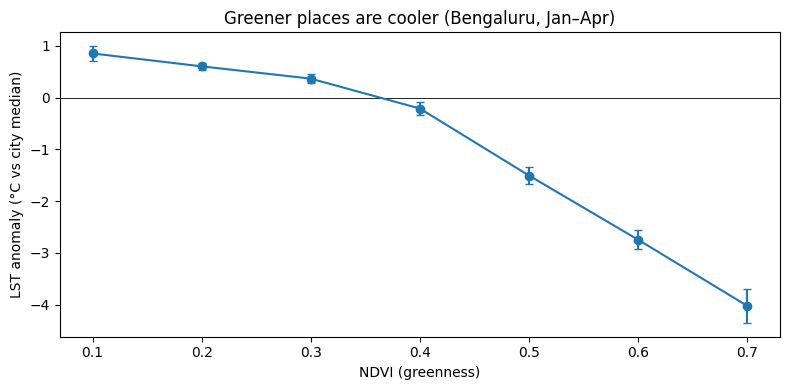

In [10]:
samp = layers.sample(region=city, scale=SCALE, numPixels=N_SAMPLE, seed=42, geometries=True, tileScale=4)
feats = samp.getInfo()['features']
px = pd.DataFrame([{**f['properties'], 'lon': f['geometry']['coordinates'][0],
                    'lat': f['geometry']['coordinates'][1]} for f in feats])
xy = gpd.GeoSeries(gpd.points_from_xy(px.lon, px.lat), crs=4326).to_crs(UTM)
b = BLOCK_KM * 1000
px['block'] = pd.factorize((xy.x // b).astype(int).astype(str) + '_' + (xy.y // b).astype(int).astype(str))[0]
land = px[px.mndwi < 0].dropna(subset=['lst_anom', 'ndvi', 'built', 'elevation']).copy()
print(f'{len(px)} pixels sampled, {len(land)} land pixels used, {land.block.nunique()} spatial blocks')

model = smf.ols('lst_anom ~ ndvi + built + elevation', land).fit(
    cov_type='cluster', cov_kwds={'groups': land.block}, use_t=True)
B_NDVI = model.params['ndvi']
B_LO, B_HI = model.conf_int().loc['ndvi']
print(model.summary().tables[1])
print(f'\n=> +0.1 NDVI is associated with {B_NDVI/10:+.2f} °C '
      f'(95% CI {B_LO/10:+.2f} to {B_HI/10:+.2f}), holding built-up and elevation fixed. R² = {model.rsquared:.2f}')

X, y = land[['ndvi', 'built', 'elevation']], land.lst_anom
pred = np.zeros(len(y))
for tr, te in GroupKFold(5).split(X, y, land.block):
    pred[te] = LinearRegression().fit(X.iloc[tr], y.iloc[tr]).predict(X.iloc[te])
rmse = np.sqrt(((y - pred) ** 2).mean())
r2cv = 1 - ((y - pred) ** 2).sum() / ((y - y.mean()) ** 2).sum()
print(f'Spatial cross-validation (whole 2 km blocks held out): R² = {r2cv:.2f}, RMSE = {rmse:.2f} °C')

pd.DataFrame({'term': model.params.index, 'coef': model.params.values, 'p': model.pvalues.values}) \
  .to_csv(os.path.join(OUT, 'city_model.csv'), index=False)
land.to_csv(os.path.join(OUT, 'city_sample_pixels.csv'), index=False)

# Chart: LST anomaly by NDVI bin
bins = np.arange(-0.05, 0.85, 0.1)
land['ndvi_bin'] = pd.cut(land.ndvi, bins)
g = land.groupby('ndvi_bin', observed=True).lst_anom.agg(['mean', 'sem', 'count'])
g = g[g['count'] >= 20]
fig, ax = plt.subplots(figsize=(8, 4))
ax.errorbar([i.mid for i in g.index], g['mean'], yerr=1.96 * g['sem'], fmt='o-', capsize=3)
ax.axhline(0, color='k', lw=0.6)
ax.set(xlabel='NDVI (greenness)', ylabel='LST anomaly (°C vs city median)',
       title='Greener places are cooler (Bengaluru, Jan–Apr)')
plt.tight_layout(); plt.savefig(os.path.join(BASE, 'figures', 'city_ndvi_vs_lst.png'), dpi=200); plt.show()

## 5. Calibration: does the model match the parks you actually measured?

For each measured park, the model's prediction is `B_NDVI × NDVI change`. If the measured cooling is in the same
range, the model is a reasonable guide for new sites.

,park,ndvi_change,measured_did,measured_p,predicted_did
0,Freedom Park,0.138,-1.324,0.052,-1.360
1,JP Park (Mathikere),-0.000,-0.482,0.749,0.000
3,Kadugodi Tree Park,0.024,0.103,0.632,-0.236


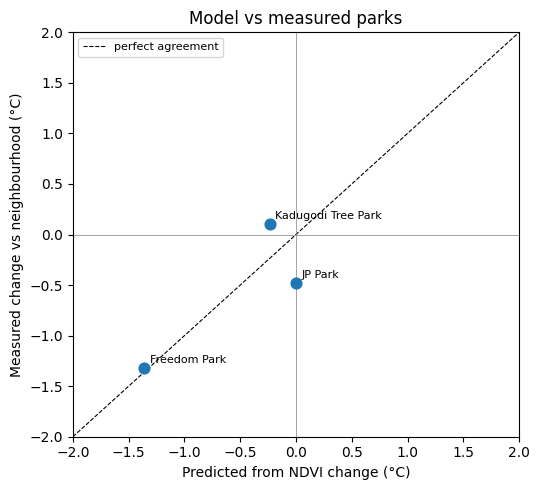

Parks whose NDVI barely changed should show ~0 cooling; a park that greened a lot should cool by roughly the predicted amount.


In [15]:
if os.path.exists(PARKS_RESULTS):
    cal = pd.read_csv(PARKS_RESULTS)
    cal = cal[(cal.status == 'ok') & ~cal.park.isin(CALIBRATION_EXCLUDE)].copy()
    cal['predicted_did'] = B_NDVI * cal.ndvi_change
    show = cal[['park', 'ndvi_change', 'site_did', 'site_p', 'predicted_did']].rename(
        columns={'site_did': 'measured_did', 'site_p': 'measured_p'})
    display(show.round(3))
    show.round(4).to_csv(os.path.join(OUT, 'calibration.csv'), index=False)

    fig, ax = plt.subplots(figsize=(5.5, 5))
    ax.scatter(show.predicted_did, show.measured_did, s=60, zorder=3)
    for _, r in show.iterrows():
        ax.annotate(r.park.split(' (')[0], (r.predicted_did, r.measured_did), fontsize=8,
                    xytext=(4, 4), textcoords='offset points')
    lim = max(2, np.nanmax(np.abs(show[['predicted_did', 'measured_did']].values)) + 0.5)
    ax.plot([-lim, lim], [-lim, lim], 'k--', lw=0.8, label='perfect agreement')
    ax.axhline(0, color='grey', lw=0.5); ax.axvline(0, color='grey', lw=0.5)
    ax.set(xlim=(-lim, lim), ylim=(-lim, lim), xlabel='Predicted from NDVI change (°C)',
           ylabel='Measured change vs neighbourhood (°C)', title='Model vs measured parks')
    ax.legend(fontsize=8); plt.tight_layout()
    plt.savefig(os.path.join(BASE, 'figures', 'calibration.png'), dpi=200); plt.show()
    print('Parks whose NDVI barely changed should show ~0 cooling; a park that greened a lot should cool by '
          'roughly the predicted amount.')
else:
    print(f'No parks results found at {PARKS_RESULTS} - run the parks notebook first, or skip this step.')

## 6. Target greenness — what does a mature park look like?

In [16]:
if TARGET_NDVI is None:
    vals = []
    for q in REFERENCE_PARKS:
        try:
            g = ox.geocode_to_gdf(q)
            v = ndvi.reduceRegion(ee.Reducer.mean(), ee.Geometry(mapping(g.geometry.iloc[0])), 30,
                                  maxPixels=1e9).get('ndvi').getInfo()
            print(f'{q.split(",")[0]}: mean NDVI {v:.3f}')
            vals.append(v)
        except Exception as e:
            print(f'{q}: could not measure ({e})')
    TARGET_NDVI = float(np.mean(vals)) if vals else 0.5
print(f'Target NDVI for a new park: {TARGET_NDVI:.3f}')

Target NDVI for a new park: 0.552


## 7. Candidate land

Open patches (Dynamic World grass / scrub / bare) with low NDVI and low built-up, at least 5 ha. Then OpenStreetMap
removes land that can't become a park (water, existing parks, airports, military, campuses …) and flags land
that may be private or in use (farmland, industrial, quarry, landfill).

In [17]:
classes = list(CANDIDATE_CLASSES)
open_land = (dw.remap(classes, [1] * len(classes), 0).eq(1)
             .And(ndvi.lt(MAX_NDVI_NOW)).And(built.lt(MAX_BUILT_NOW)))
vec = (open_land.selfMask().rename('open').reduceToVectors(
           geometry=city, scale=30, geometryType='polygon', eightConnected=True,
           maxPixels=1e10, tileScale=4)
       .map(lambda f: f.set('area_ha', f.geometry().area(5).divide(1e4)))
       .filter(ee.Filter.gte('area_ha', MIN_SITE_HA))
       .sort('area_ha', False).limit(MAX_CANDIDATES))
print('Open patches >=', MIN_SITE_HA, 'ha:', vec.size().getInfo())

def manual_fc():
    feats = []
    for i, c in enumerate(MY_CANDIDATES):
        if 'geojson' in c:
            g = gpd.read_file(os.path.join(BASE, c['geojson'])).to_crs(4326).geometry.iloc[0]
            geom = ee.Geometry(mapping(g))
        else:
            lat, lon = c['point']
            geom = ee.Geometry.Point([lon, lat]).buffer(np.sqrt(c['area_ha'] * 1e4 / np.pi), 5)
        feats.append(ee.Feature(geom, {'name': c['name'], 'source': 'manual'}).set('system:index', f'manual_{i}'))
    return ee.FeatureCollection(feats)

def score_inputs(fc):
    """Site, 500 m buffer and 1 km neighbourhood statistics for every polygon in fc."""
    fc = ee.FeatureCollection(fc).map(lambda f: f.setGeometry(f.geometry().simplify(30)))
    site = layers.select(['lst_anom', 'ndvi', 'built']).reduceRegions(fc, ee.Reducer.mean(), 30, tileScale=4)
    buf = fc.map(lambda f: f.setGeometry(f.geometry().buffer(BENEFIT_RADIUS, 10)))
    buf = layers.select(['lst_anom', 'pop_density']).reduceRegions(buf, ee.Reducer.mean(), 30, tileScale=4)
    nb = fc.map(lambda f: f.setGeometry(f.geometry().buffer(1000, 10).difference(f.geometry(), 10)))
    nb = ndvi.reduceRegions(nb, ee.Reducer.mean(), 30, tileScale=4)

    site_i = site.getInfo()['features']
    gdf = gpd.GeoDataFrame.from_features(site_i, crs=4326)
    gdf['cid'] = [f['id'] for f in site_i]
    gdf = gdf.rename(columns={'lst_anom': 'lst_anom_site', 'ndvi': 'ndvi_site', 'built': 'built_site'})
    b = pd.DataFrame([{'cid': f['id'], 'lst_anom_500m': f['properties'].get('lst_anom'),
                       'pop_density_500m': f['properties'].get('pop_density')} for f in buf.getInfo()['features']])
    n = pd.DataFrame([{'cid': f['id'], 'ndvi_1km': f['properties'].get('mean')}
                      for f in nb.getInfo()['features']])
    return gdf.merge(b, on='cid').merge(n, on='cid')

cand = score_inputs(vec)
cand['source'] = 'auto'
cand['name'] = ''
if MY_CANDIDATES:
    man = score_inputs(manual_fc())
    cand = pd.concat([cand, man], ignore_index=True)
cand = gpd.GeoDataFrame(cand, geometry='geometry', crs=4326)
cand['area_ha'] = cand.to_crs(UTM).area / 1e4
print(len(cand), 'candidates with statistics')

Open patches >= 5 ha: 24
24 candidates with statistics


In [18]:
def osm_union(tags):
    try:
        f = ox.features_from_polygon(city_gdf.geometry.iloc[0], tags=tags)
        f = f[f.geometry.geom_type.isin(['Polygon', 'MultiPolygon'])]
        if f.empty:
            return None
        f = f.to_crs(UTM)
        return f.union_all() if hasattr(f, 'union_all') else f.unary_union
    except Exception as e:
        print('   OSM query failed:', str(e)[:80])
        return None

print('Downloading OpenStreetMap land-use layers (can take a minute)...')
no_go = osm_union(NO_GO_TAGS)
flag = {v: osm_union({'landuse': [v]}) for v in FLAG_TAGS['landuse']}

c_utm = cand.to_crs(UTM)
cand['no_go_overlap'] = (c_utm.intersection(no_go).area / c_utm.area).values if no_go is not None else 0.0
cand['flags'] = ''
for k, u in flag.items():
    if u is not None:
        hit = (c_utm.intersection(u).area / c_utm.area).values > 0.2
        cand.loc[hit, 'flags'] = cand.loc[hit, 'flags'] + k + ' '
keep = (cand.no_go_overlap <= MAX_NO_GO_OVERLAP) | (cand.source == 'manual')
print(f'Removed {int((~keep).sum())} candidates overlapping water, parks, airports, military, campuses etc.')
cand = cand[keep].copy()
print(len(cand), 'candidates remain')

Removed 14 candidates overlapping water, parks, airports, military, campuses etc.
10 candidates remain


## 8. Score and rank

- **cooling** — expected on-site cooling if the patch reached the target park NDVI: `−B_NDVI × (TARGET − NDVI now)`
- **residents** — people living within 500 m
- **heat** — how much hotter than the city median the 500 m surroundings are today
- **green_deficit** — how un-green the 1 km neighbourhood is (target NDVI − neighbourhood NDVI)
- **priority score** — weighted mean of the four, each converted to a 0–1 percentile (weights in Section 1)
- **benefit** — cooling × residents, in "person-°C", a simple single number for comparison

In [19]:
buf_area_km2 = cand.to_crs(UTM).buffer(BENEFIT_RADIUS).area / 1e6
cand['residents_500m'] = cand.pop_density_500m * buf_area_km2.values
cand['ndvi_gain'] = (TARGET_NDVI - cand.ndvi_site).clip(lower=0)
cand['cooling_c'] = -B_NDVI * cand.ndvi_gain
cand['cooling_lo'] = -B_HI * cand.ndvi_gain       # 95% range from the model coefficient
cand['cooling_hi'] = -B_LO * cand.ndvi_gain
cand['heat'] = cand.lst_anom_500m
cand['green_deficit'] = TARGET_NDVI - cand.ndvi_1km
cand['benefit_person_c'] = cand.cooling_c * cand.residents_500m

factors = {'cooling': 'cooling_c', 'residents': 'residents_500m', 'heat': 'heat', 'green_deficit': 'green_deficit'}
cand['score'] = sum(WEIGHTS[k] * cand[c].rank(pct=True) for k, c in factors.items()) / sum(WEIGHTS.values())
cand = cand.sort_values('score', ascending=False).reset_index(drop=True)
cand['rank'] = np.arange(1, len(cand) + 1)
cent = cand.to_crs(UTM).centroid.to_crs(4326)
cand['lat'], cand['lon'] = cent.y.round(5), cent.x.round(5)

def nearby_place(lat, lon):
    try:
        r = requests.get('https://nominatim.openstreetmap.org/reverse',
                         params={'lat': lat, 'lon': lon, 'format': 'json', 'zoom': 16},
                         headers={'User-Agent': 'bengaluru-regreening-student-project'}, timeout=20).json()
        a = r.get('address', {})
        return a.get('suburb') or a.get('neighbourhood') or a.get('village') or a.get('road') or ''
    except Exception:
        return ''

TOP_N = 15
for i in cand.index[:TOP_N]:
    if not cand.at[i, 'name']:
        cand.at[i, 'name'] = 'near ' + nearby_place(cand.at[i, 'lat'], cand.at[i, 'lon'])
        time.sleep(1.1)        # Nominatim allows 1 request per second

cols = ['rank', 'name', 'source', 'area_ha', 'ndvi_site', 'cooling_c', 'cooling_lo', 'cooling_hi',
        'residents_500m', 'heat', 'green_deficit', 'benefit_person_c', 'score', 'flags', 'lat', 'lon']
table = cand[cols].round({'area_ha': 1, 'ndvi_site': 3, 'cooling_c': 2, 'cooling_lo': 2, 'cooling_hi': 2,
                          'residents_500m': 0, 'heat': 2, 'green_deficit': 3, 'benefit_person_c': 0, 'score': 3})
table.to_csv(os.path.join(OUT, 'candidates_ranked.csv'), index=False)
cand.drop(columns=['cid']).to_file(os.path.join(OUT, 'candidates_ranked.geojson'), driver='GeoJSON')
print(f'Top {TOP_N} candidate sites (full list saved to data/site_selection/candidates_ranked.csv):')
display(table.head(TOP_N))

Top 15 candidate sites (full list saved to data/site_selection/candidates_ranked.csv):


,rank,name,source,area_ha,ndvi_site,cooling_c,cooling_lo,cooling_hi,residents_500m,heat,green_deficit,benefit_person_c,score,flags,lat,lon
0,1,near Deepanjali Nagara,auto,6.2,0.206,3.41,3.20,3.62,14053.0,0.71,0.287,47936.0,0.770,,12.94351,77.53475
1,2,near Kogilu,auto,5.0,0.169,3.78,3.54,4.02,820.0,1.19,0.279,3098.0,0.735,quarry,13.10396,77.64877
2,3,near Gangenahalli,auto,7.5,0.169,3.78,3.54,4.01,31054.0,-0.50,0.167,117269.0,0.695,,13.01275,77.58588
3,4,near Kogilu,auto,9.1,0.233,3.15,2.95,3.34,14827.0,-0.41,0.236,46665.0,0.680,,13.10812,77.61600
4,5,near Akash Ward,auto,15.0,0.274,2.74,2.57,2.92,4013.0,1.25,0.231,11011.0,0.635,,13.12415,77.59704
5,6,near Kogilu,auto,8.7,0.291,2.58,2.42,2.74,3804.0,2.29,0.250,9803.0,0.570,,13.09251,77.64358
6,7,near Anjanapura,auto,26.0,0.278,2.71,2.54,2.88,235.0,3.49,0.226,635.0,0.525,quarry,12.84335,77.56924
7,8,near Gunjur,auto,15.7,0.284,2.65,2.48,2.82,155.0,0.30,0.210,412.0,0.335,,12.92595,77.70896
8,9,near Gunjur,auto,10.3,0.315,2.34,2.19,2.49,107.0,1.79,0.243,250.0,0.330,,12.92521,77.74449
9,10,near Panathur,auto,6.7,0.292,2.57,2.41,2.73,36.0,1.21,0.190,92.0,0.225,,12.92052,77.70689


## 9. Maps & charts

Map(center=[12.97, 77.59], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright'…

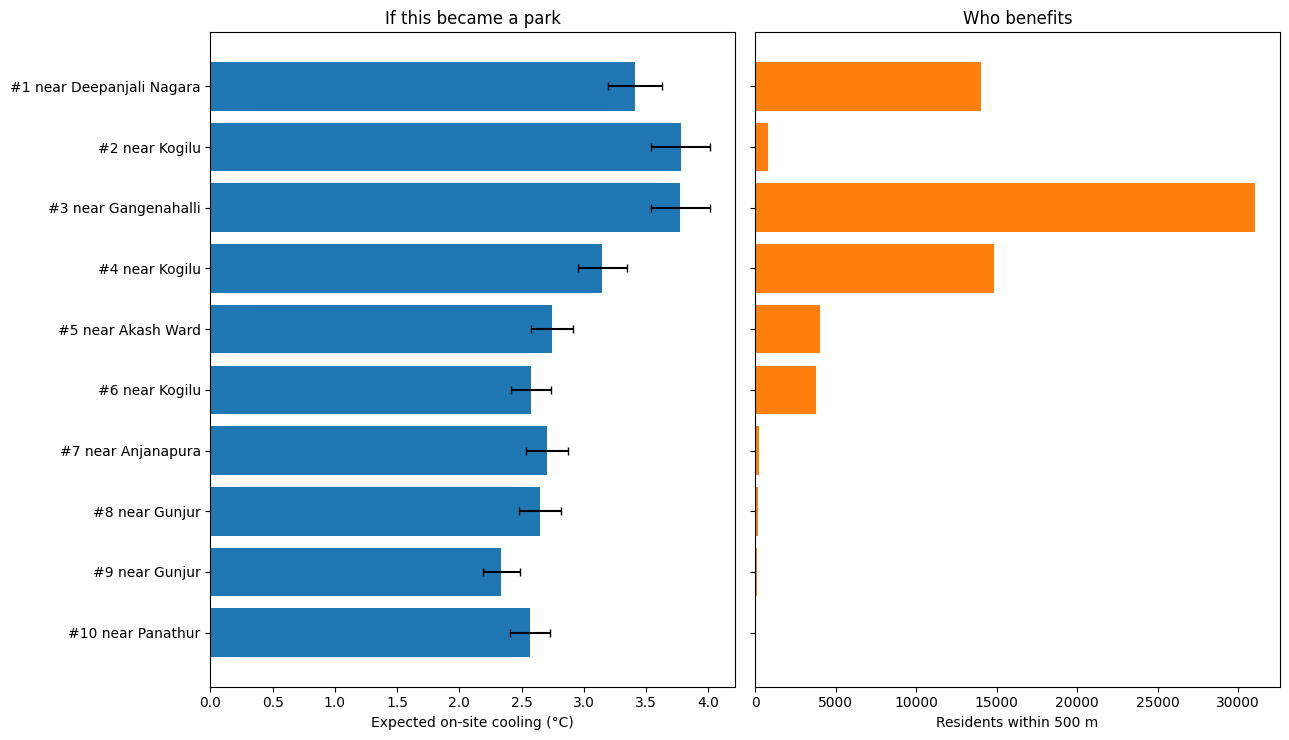

Saved figures/candidates_on_heat_map.png and figures/top_candidates.png


In [20]:
top = cand.head(TOP_N)
top_fc = ee.FeatureCollection(json.loads(top[['rank', 'geometry']].to_json()))
rest_fc = ee.FeatureCollection(json.loads(cand.iloc[TOP_N:][['rank', 'geometry']].to_json()))

m = base_map()
m.addLayer(lst_anom.clip(city), V_ANOM, 'LST anomaly (°C vs city median)')
m.addLayer(ndvi.clip(city), V_NDVI, 'NDVI', False)
m.addLayer(rest_fc.style(color='ffffff', fillColor='ffffff40', width=1), {}, 'Other candidates')
m.addLayer(top_fc.style(color='00ff00', fillColor='00ff0060', width=2), {}, f'Top {TOP_N} candidates')
m.addLayer(city_outline, {}, 'City boundary')
m.add_layer_control()
display(m)

save_thumb(lst_anom.clip(city).visualize(**V_ANOM).blend(city_outline)
           .blend(top_fc.style(color='00ff00', fillColor='00ff0080', width=3)),
           city.bounds(), os.path.join(BASE, 'figures', 'candidates_on_heat_map.png'), dims=1400)

t = top.iloc[::-1]
labels = [f"#{r} {n}"[:40] for r, n in zip(t['rank'], t['name'])]
fig, axes = plt.subplots(1, 2, figsize=(13, 0.4 * TOP_N + 1.5), sharey=True)
axes[0].barh(labels, t.cooling_c, xerr=[t.cooling_c - t.cooling_lo, t.cooling_hi - t.cooling_c],
             color='tab:blue', capsize=3)
axes[0].set(xlabel='Expected on-site cooling (°C)', title='If this became a park')
axes[1].barh(labels, t.residents_500m, color='tab:orange')
axes[1].set(xlabel='Residents within 500 m', title='Who benefits')
plt.tight_layout(); plt.savefig(os.path.join(BASE, 'figures', 'top_candidates.png'), dpi=200); plt.show()
print('Saved figures/candidates_on_heat_map.png and figures/top_candidates.png')

## 10. "What if" — the top site as a park

In [21]:
best = cand.iloc[0]
best_geom = ee.Geometry(mapping(best.geometry))
inside = ee.Image.constant(0).paint(ee.FeatureCollection([ee.Feature(best_geom)]), 1)
delta = ndvi.multiply(-1).add(TARGET_NDVI).max(0).multiply(B_NDVI)          # °C, negative = cooler
after = lst_anom.add(delta.multiply(inside)).rename('lst_anom')
region = best_geom.buffer(1500, 10).bounds()
outline = ee.FeatureCollection([ee.Feature(best_geom)]).style(color='black', fillColor='00000000', width=2)

for name, img in [('whatif_before', lst_anom), ('whatif_after', after)]:
    save_thumb(img.visualize(**V_ANOM).blend(outline), region, os.path.join(BASE, 'figures', f'{name}.png'), 700)

m2 = base_map(center=(best.lat, best.lon), zoom=15)
m2.addLayer(lst_anom.clip(region), V_ANOM, 'Today')
m2.addLayer(after.clip(region), V_ANOM, 'If it became a park')
m2.addLayer(outline, {}, 'Site')
m2.add_layer_control()
print(f"#1 {best['name']} ({best.area_ha:.0f} ha): NDVI {best.ndvi_site:.2f} -> {TARGET_NDVI:.2f}, "
      f"expected cooling {best.cooling_c:.1f} °C (range {best.cooling_lo:.1f}-{best.cooling_hi:.1f}), "
      f"{best.residents_500m:,.0f} residents within {BENEFIT_RADIUS} m.")
print('Saved figures/whatif_before.png and figures/whatif_after.png. Toggle the layers to compare.')
display(m2)

#1 near Deepanjali Nagara (6 ha): NDVI 0.21 -> 0.55, expected cooling 3.4 °C (range 3.2-3.6), 14,053 residents within 500 m.
Saved figures/whatif_before.png and figures/whatif_after.png. Toggle the layers to compare.


Map(center=[np.float64(12.94351), np.float64(77.53475)], controls=(WidgetControl(options=['position', 'transpa…

## 11. How to read and report this

- **Check the top sites on the satellite map.** Automatic land cover makes mistakes: a dry lake bed, a fenced
  private plot or a construction site can look like "open land". Note anything you remove and why.
- **Cooling numbers are model predictions** from the city-wide NDVI–LST relationship, checked against the parks you
  measured. They assume the site reaches the greenness of a mature park, which needs tree canopy rather than lawn.
- **Measured spill-over was small.** In the parks notebook the cooling was mostly on the site itself, so "residents
  within 500 m" here means *people who could use a cooler space nearby*, not people whose homes get cooler.
- **Sensitivity:** change `WEIGHTS`, `BENEFIT_RADIUS` or `TARGET_NDVI` and see whether the top 5 stays stable. Sites
  that stay near the top under different weights are the strongest recommendations.